In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import LabelEncoder

# Carregar os dados
df = pd.read_csv("crop_yield.csv")

print(df.head())

  Region Soil_Type     Crop  Rainfall_mm  Temperature_Celsius  \
0   West     Sandy   Cotton   897.077239            27.676966   
1  South      Clay     Rice   992.673282            18.026142   
2  North      Loam   Barley   147.998025            29.794042   
3  North     Sandy  Soybean   986.866331            16.644190   
4  South      Silt    Wheat   730.379174            31.620687   

   Fertilizer_Used  Irrigation_Used Weather_Condition  Days_to_Harvest  \
0            False             True            Cloudy              122   
1             True             True             Rainy              140   
2            False            False             Sunny              106   
3            False             True             Rainy              146   
4             True             True            Cloudy              110   

   Yield_tons_per_hectare  
0                6.555816  
1                8.527341  
2                1.127443  
3                6.517573  
4                7.24825

In [25]:
import pandas as pd
import statsmodels.api as sm
from sklearn.preprocessing import LabelEncoder

# Carregar o dataset
df = pd.read_csv("crop_yield.csv")

# Converter colunas booleanas para inteiros
bool_columns = df.select_dtypes(include='bool').columns
df[bool_columns] = df[bool_columns].astype(int)

# Identificar colunas categóricas do tipo string
categorical_columns = df.select_dtypes(include='object').columns

# Aplicar LabelEncoder apenas nas colunas categóricas
le = LabelEncoder()
for col in categorical_columns:
    df[col] = le.fit_transform(df[col].astype(str))

# Definir variáveis independentes (X) e dependente (y)
X = df[["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest", "Soil_Type", "Fertilizer_Used", "Irrigation_Used", "Weather_Condition"]]
y = df["Yield_tons_per_hectare"]

# Remover linhas com valores ausentes
X = X.dropna()
y = y.loc[X.index]

# Adicionar constante para o intercepto
X = sm.add_constant(X)

# Garantir que todas as variáveis estejam em formato numérico
X = X.apply(pd.to_numeric)
y = pd.to_numeric(y)

# Ajustar o modelo de regressão linear
model = sm.OLS(y, X).fit()

# Exibir o resumo do modelo
print(model.summary())

                              OLS Regression Results                              
Dep. Variable:     Yield_tons_per_hectare   R-squared:                       0.913
Model:                                OLS   Adj. R-squared:                  0.913
Method:                     Least Squares   F-statistic:                 1.499e+06
Date:                    Wed, 08 Oct 2025   Prob (F-statistic):               0.00
Time:                            15:12:18   Log-Likelihood:            -7.2675e+05
No. Observations:                 1000000   AIC:                         1.454e+06
Df Residuals:                      999992   BIC:                         1.454e+06
Df Model:                               7                                         
Covariance Type:                nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------

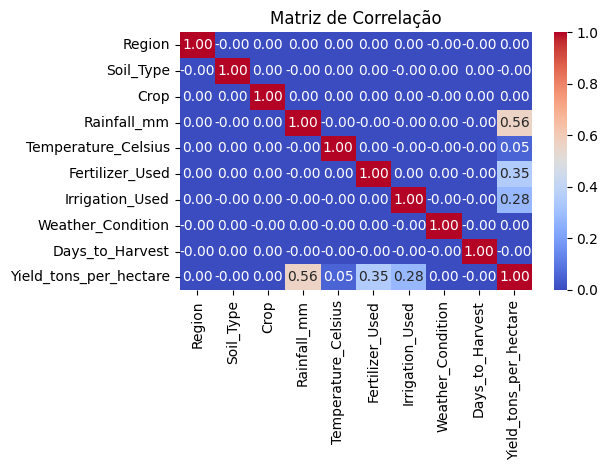

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold

# Load the dataset
df = pd.read_csv("crop_yield.csv")

# Identificar colunas categóricas (tipo object)
categorical_columns = df.select_dtypes(include='object').columns

# Aplicar LabelEncoder em cada coluna categórica
le = LabelEncoder()
for col in categorical_columns:
    df[col] = le.fit_transform(df[col].astype(str))

sns.heatmap(df.corr(method='kendall'), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de Correlação")
plt.tight_layout()
plt.show()


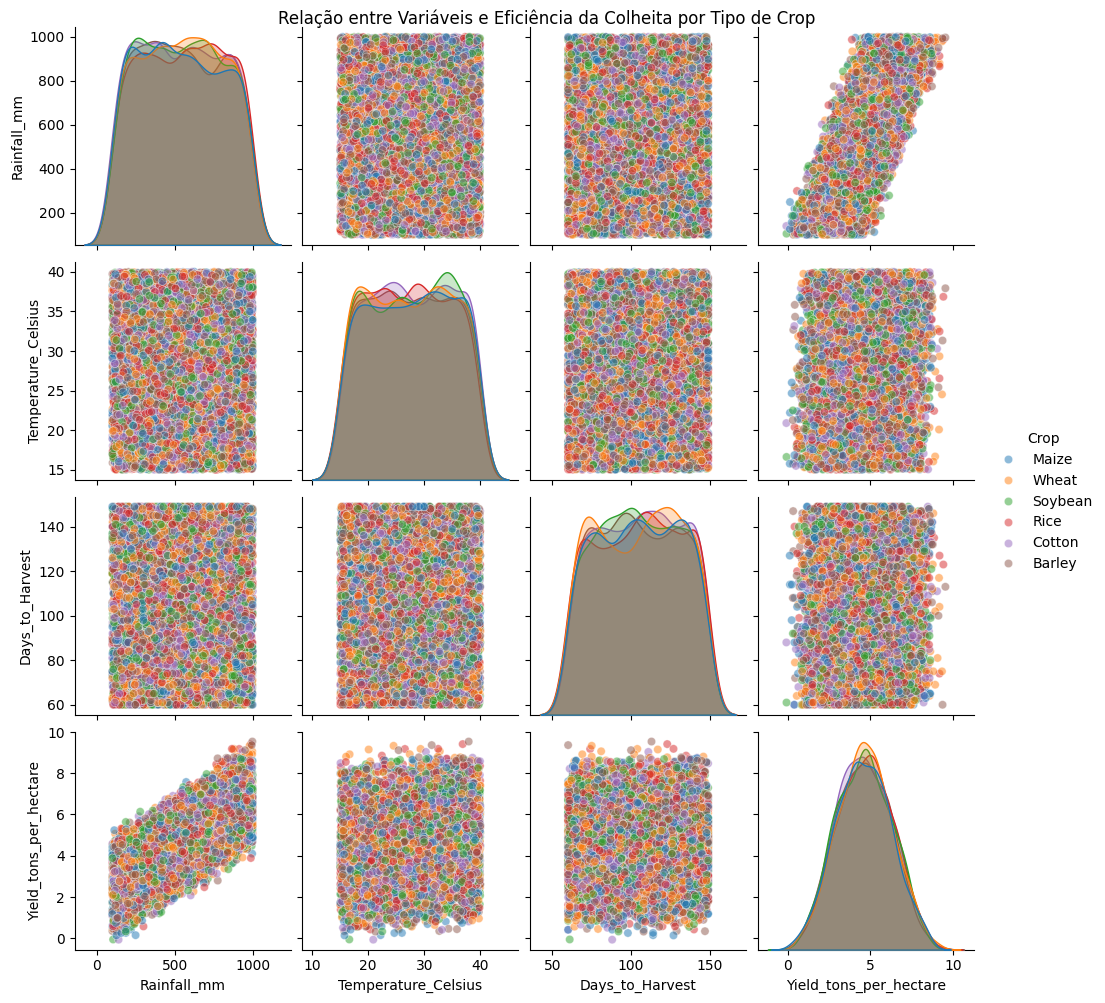

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# Carregar o dataset
df = pd.read_csv("crop_yield.csv")
df = df.sample(10000)

# Identificar colunas categóricas, excluindo 'Crop'
categorical_columns = df.select_dtypes(include='object').columns.drop('Crop')

# Aplicar LabelEncoder nas demais colunas categóricas
le = LabelEncoder()
for col in categorical_columns:
    df[col] = le.fit_transform(df[col].astype(str))

# Gerar o pairplot com hue baseado em 'Crop'
sns.pairplot(df, vars=["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest", "Yield_tons_per_hectare"], hue='Crop', plot_kws={'alpha':0.5})
plt.suptitle("Relação entre Variáveis e Eficiência da Colheita por Tipo de Crop", y = 1)
plt.show()

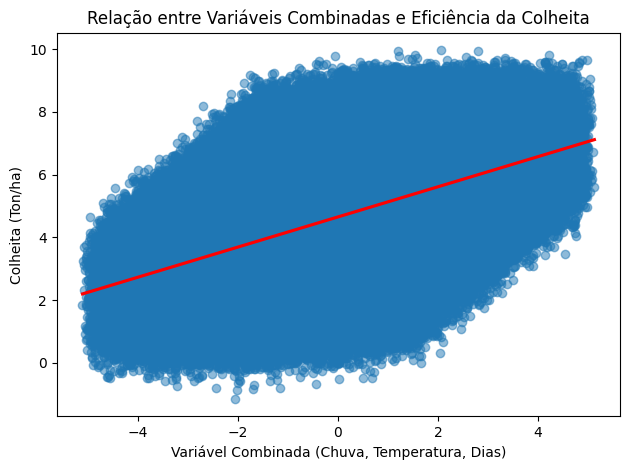

In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold

# Load the dataset
df = pd.read_csv("crop_yield.csv")

# Identificar colunas categóricas (tipo object)
categorical_columns = df.select_dtypes(include='object').columns

# Padronizar as variáveis
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest"]])

# Criar uma variável combinada
df["Combined_X"] = X_scaled.sum(axis=1)

# Plotar a regressão
sns.regplot(data=df, x="Combined_X", y="Yield_tons_per_hectare", scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.xlabel("Variável Combinada (Chuva, Temperatura, Dias)")
plt.ylabel("Colheita (Ton/ha)")
plt.title("Relação entre Variáveis Combinadas e Eficiência da Colheita")
plt.tight_layout()
plt.show()



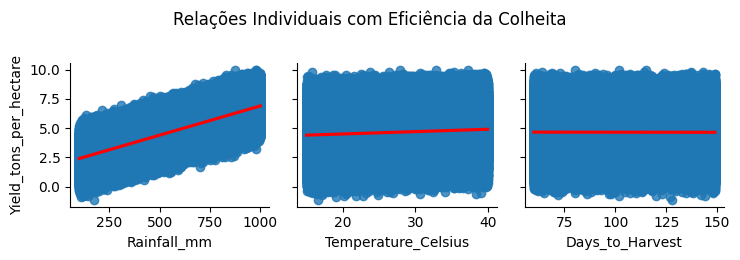

In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold

# Load the dataset
df = pd.read_csv("crop_yield.csv")

# Identificar colunas categóricas (tipo object)
categorical_columns = df.select_dtypes(include='object').columns

X = df[["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest",]]

# Aplicar LabelEncoder em cada coluna categórica
le = LabelEncoder()
for col in categorical_columns:
    df[col] = le.fit_transform(df[col].astype(str))

sns.pairplot(df, x_vars=["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest"], y_vars="Yield_tons_per_hectare", kind="reg", plot_kws={'line_kws':{'color':'red'}})
plt.suptitle("Relações Individuais com Eficiência da Colheita", y=1.02)
plt.tight_layout()
plt.show()


KeyError: 'Fertilezer_Used'

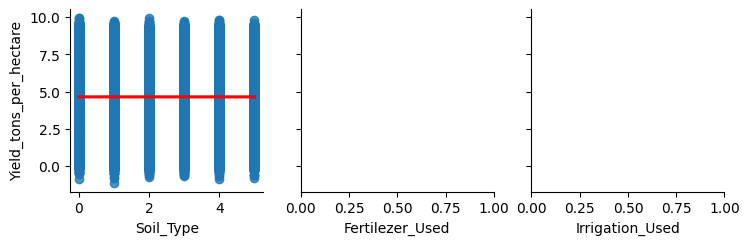

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold

# Load the dataset
df = pd.read_csv("crop_yield.csv")

# Identificar colunas categóricas (tipo object)
categorical_columns = df.select_dtypes(include='object').columns

X = df[["Soil_Type", "Fertilizer_Used", "Irrigation_Used",]]

# Aplicar LabelEncoder em cada coluna categórica
le = LabelEncoder()
for col in categorical_columns:
    df[col] = le.fit_transform(df[col].astype(str))

sns.pairplot(df, x_vars=["Soil_Type", "Fertilizer_Used", "Irrigation_Used"], y_vars="Yield_tons_per_hectare", kind="reg", plot_kws={'line_kws':{'color':'red'}})
plt.suptitle("Relações Individuais com Eficiência da Colheita", y=1.02)
plt.tight_layout()
plt.show()

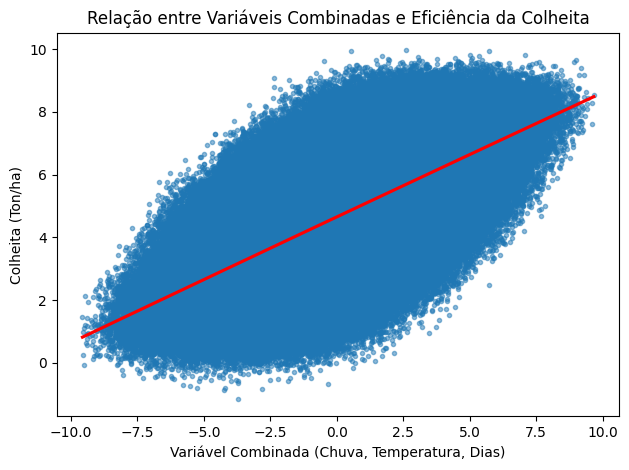

In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold

# Load the dataset
df = pd.read_csv("crop_yield.csv")

# Identificar colunas categóricas (tipo object)
categorical_columns = df.select_dtypes(include='object').columns

# Aplicar LabelEncoder em cada coluna categórica
le = LabelEncoder()
for col in categorical_columns:
    df[col] = le.fit_transform(df[col].astype(str))

# Padronizar as variáveis
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest", "Soil_Type", "Fertilizer_Used", "Irrigation_Used", "Weather_Condition"]])

# Criar uma variável combinada
df["Combined_X"] = X_scaled.sum(axis=1)

# Plotar a regressão
sns.regplot(data=df, x="Combined_X", y="Yield_tons_per_hectare", scatter_kws={'alpha':0.5}, line_kws={'color':'red'}, order=2, marker='.')
plt.xlabel("Variável Combinada (Chuva, Temperatura, Dias)")
plt.ylabel("Colheita (Ton/ha)")
plt.title("Relação entre Variáveis Combinadas e Eficiência da Colheita")
plt.tight_layout()
plt.show()